# Figure 6 — combined
P-error barplots for external validation sets.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure code_repository/notebooks is importable
HERE = Path.cwd().resolve()
if (HERE / 'notebooks').exists():
    SRC_ROOT = HERE / 'notebooks'
elif (HERE / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE / 'code_repository' / 'notebooks'
elif (HERE.parent / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE.parent / 'code_repository' / 'notebooks'
else:
    SRC_ROOT = None
if SRC_ROOT is not None:
    sys.path.insert(0, str(SRC_ROOT))

from analysis.plot_style import apply_style, style_axes, save_figure, set_save_dir

apply_style()

ROOT = Path.cwd().resolve()
if (ROOT / 'Data').exists():
    PROJECT_ROOT = ROOT
elif (ROOT.parent / 'Data').exists():
    PROJECT_ROOT = ROOT.parent
else:
    PROJECT_ROOT = ROOT

FIGURE_ID = 'figure6'
SAVE_DIR = set_save_dir(PROJECT_ROOT, FIGURE_ID)


In [2]:
# ---- Config ----
DISPLAY_ORDER = [
    'Fatty acid','Nitrofurans','Folic acid','Membrane',
    'RNA synth.','LPS synth.','DNA repl.','Cell wall','Protein syn.'
]

# Figure-2 palette (consistent across figures)
COLORS = [
    "#264653", "#287271", "#2a9d8f", "#7fb48a",
    "#e9c46a", "#c6902e", "#f28e2b", "#e76f51", "#d1495b"
]

CANON_MAP = {
    'Fatty acid':      ['Fatty acid','Fatty acid synthesis'],
    'Nitrofurans':     ['Nitrofurans'],
    'Folic acid':      ['Folic acid','Folic acid metabolism','Folic acid biosynthesis'],
    'Membrane':        ['Membrane','Membrane disruption','Membrane integrity'],
    'RNA synth.':      ['RNA synth.','RNA Synthesis','RNA synthesis'],
    'LPS synth.':      ['LPS synth.','lipopolysaccharide synthesis','LPS synthesis'],
    'DNA repl.':       ['DNA repl.','DNA replication','DNA Replication'],
    'Cell wall':       ['Cell wall','Cell wall biosynthesis','Cell-wall biosynthesis'],
    'Protein syn.':    ['Protein syn.','Protein synthesis','Protein Synthesis'],
}

MOA_COLOR = {DISPLAY_ORDER[i]: COLORS[i] for i in range(len(DISPLAY_ORDER))}


def canonical_moa(moa: str) -> str:
    if moa is None:
        return "Unknown"
    s = str(moa).strip()
    for canon, variants in CANON_MAP.items():
        if s in variants:
            return canon
    return s


def moa_color(moa: str) -> str:
    canon = canonical_moa(moa)
    return MOA_COLOR.get(canon, "#888888")


# Threshold from meta artifact (shared across these runs)
META_ARTIFACTS = [
    PROJECT_ROOT / "models/uncertainty_estimator_adapted/meta_artifact.json",
]
meta_threshold = None
for p in META_ARTIFACTS:
    if p.exists():
        import json
        meta_threshold = float(json.loads(p.read_text()).get("meta_threshold", 0.4))
        break
if meta_threshold is None:
    meta_threshold = 0.4


# Source CSVs
DATASETS = {
    "a": PROJECT_ROOT / "predictions/eclipse_data/non_sig_reduced/uncertainty_meta_apply/compound_uncertainty_meta.csv",
    "b": PROJECT_ROOT / "predictions/eclipse_data/sig_reduced/uncertainty_meta_apply/compound_uncertainty_meta.csv",
    "c": PROJECT_ROOT / "predictions/external_data/non_sig_reduced/uncertainty_meta_apply/compound_uncertainty_meta.csv",
    "d": PROJECT_ROOT / "predictions/external_data/sig_reduced/uncertainty_meta_apply/compound_uncertainty_meta.csv",
}

ORDER_JH = ["JH29", "JH55", "JH6"]
ORDER_ANTIB = ["Ciprofloxacin", "Kanamycin", "Imipenem", "Cefotaxime"]


LABEL_MAP_JH = {
    "JH29": "Ciprofloxacin",
    "JH55": "Kanamycin",
    "JH6": "Imipenem",
}




In [3]:
def plot_p_error_panel(ax, df, order, title=None, show_legend=False, label_map=None):
    df = df.copy()
    df["CanonMoA"] = df["PredictedMoA"].map(canonical_moa)
    df["base_color"] = df["CanonMoA"].map(moa_color)
    df["color"] = np.where(df["p_error"] >= meta_threshold, "#aaaaaa", df["base_color"])

    df = df.set_index("CompoundID").reindex(order).reset_index()

    x = np.arange(len(df))
    ax.bar(x, df["p_error"], color=df["color"], edgecolor="black", linewidth=0.4)
    ax.axhline(meta_threshold, color="red", linestyle="--", linewidth=1.0)

    ax.set_ylabel("Predicted error probability (p_error)")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.set_xticks(x)
    labels = df["CompoundID"].astype(str).tolist()
    if label_map:
        labels = [label_map.get(cid, cid) for cid in labels]
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_title(title)

    if show_legend:
        handles = [
            plt.Rectangle((0, 0), 1, 1, facecolor=MOA_COLOR[m], edgecolor="black", label=m)
            for m in DISPLAY_ORDER
        ]
        handles.append(
            plt.Rectangle((0, 0), 1, 1, facecolor="#aaaaaa", edgecolor="black",
                          label="Uncertain (p_error ≥ threshold)")
        )
        ax.legend(handles=handles, title="Predicted MoA / Uncertainty",
                  frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1.0))

    style_axes(ax)


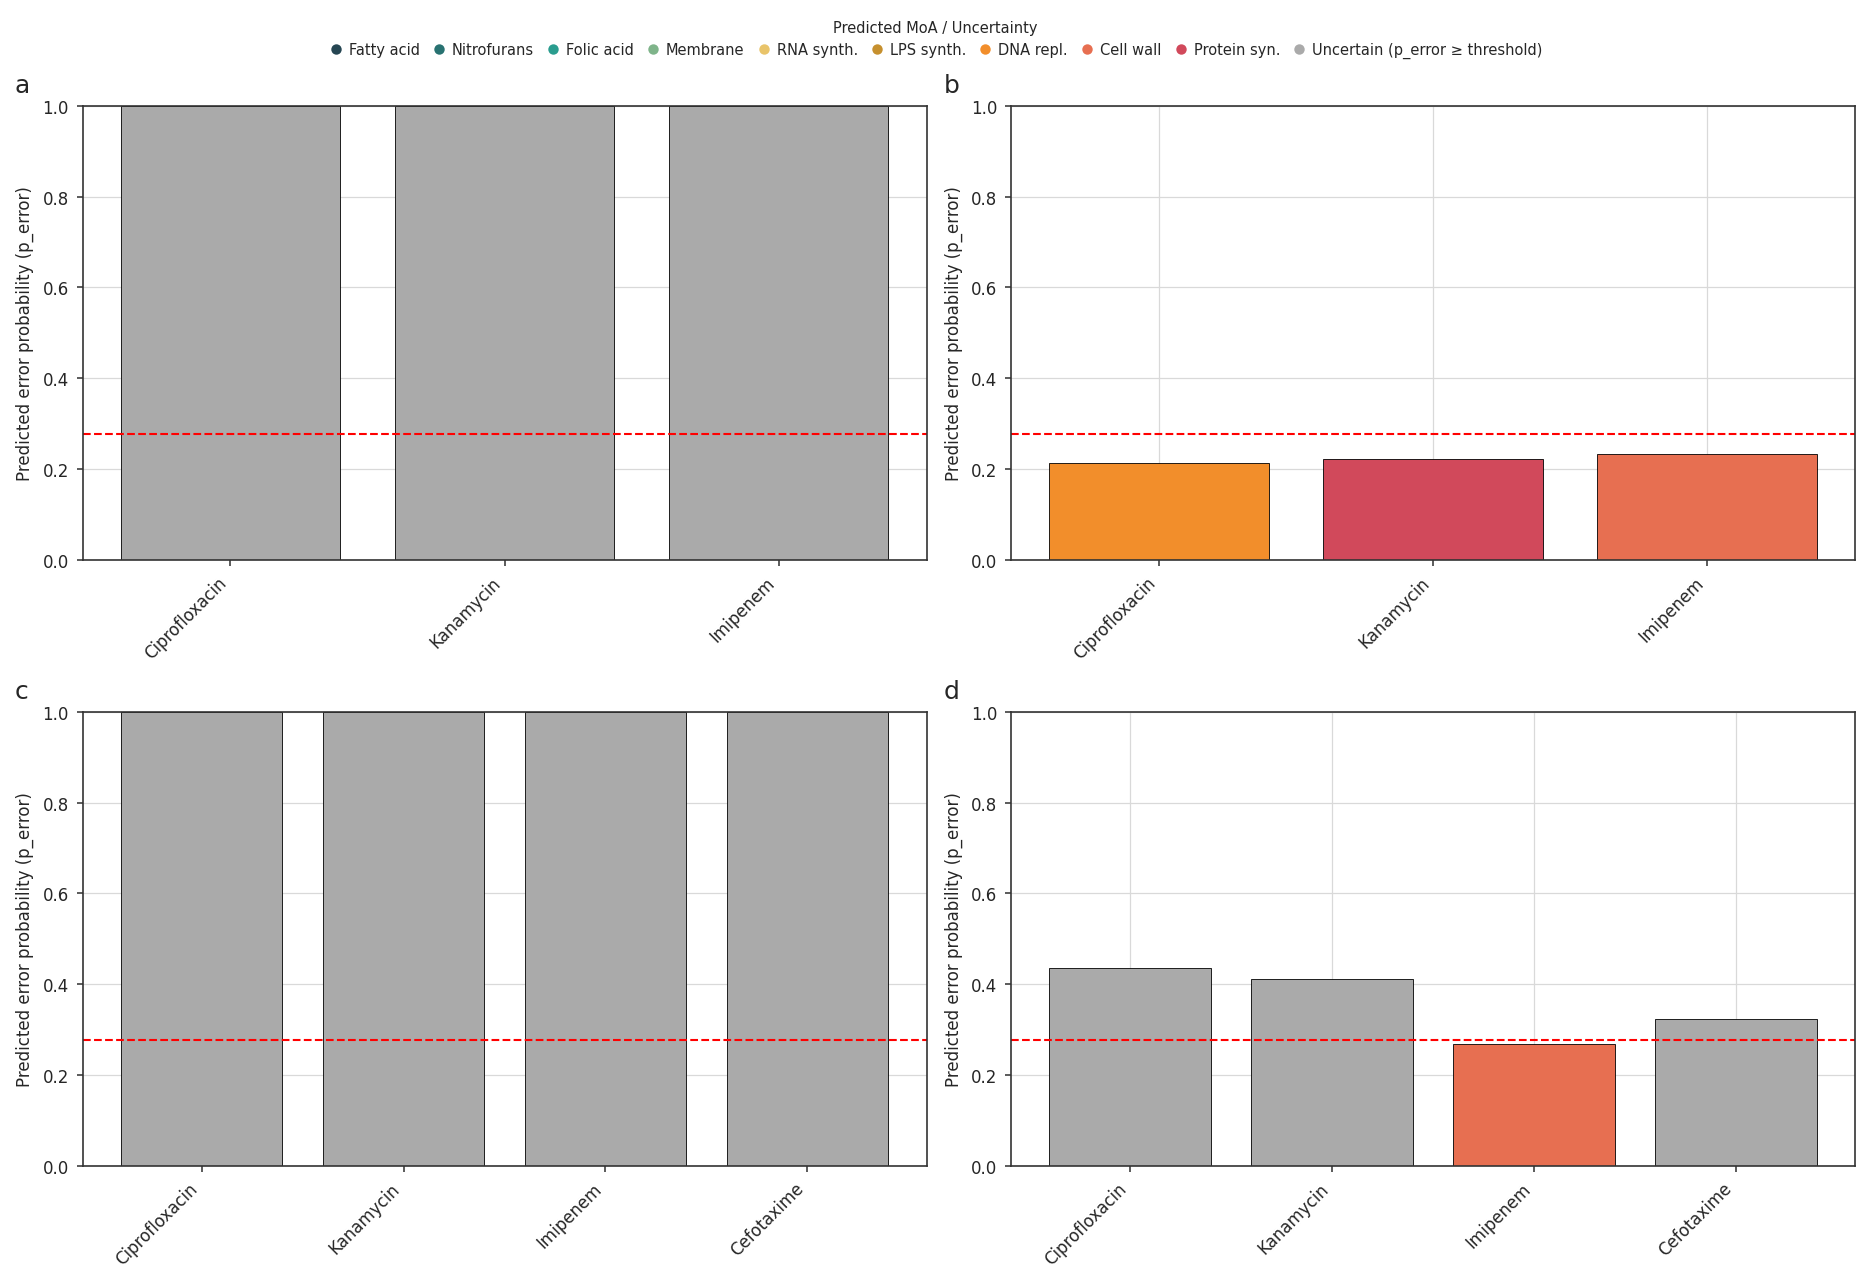

In [4]:
# ---- Build combined figure ----

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))
axes = axes.reshape(2, 2)

# Panel a
_df_a = pd.read_csv(DATASETS["a"])
plot_p_error_panel(axes[0, 0], _df_a, ORDER_JH, label_map=LABEL_MAP_JH, title= "")
axes[0, 0].text(-0.08, 1.03, 'a', transform=axes[0, 0].transAxes, fontsize=12)

# Panel b
_df_b = pd.read_csv(DATASETS["b"])
plot_p_error_panel(axes[0, 1], _df_b, ORDER_JH, label_map=LABEL_MAP_JH, title= "")
axes[0, 1].text(-0.08, 1.03, 'b', transform=axes[0, 1].transAxes, fontsize=12)

# Panel c
_df_c = pd.read_csv(DATASETS["c"])
plot_p_error_panel(axes[1, 0], _df_c, ORDER_ANTIB, title= "")
axes[1, 0].text(-0.08, 1.03, 'c', transform=axes[1, 0].transAxes, fontsize=12)

# Panel d
_df_d = pd.read_csv(DATASETS["d"])
plot_p_error_panel(axes[1, 1], _df_d, ORDER_ANTIB, title= "")
axes[1, 1].text(-0.08, 1.03, 'd', transform=axes[1, 1].transAxes, fontsize=12)


# Shared legend (dots) at top
legend_handles = [
    plt.Line2D([0], [0], marker='o', linestyle='', color='none',
               markerfacecolor=MOA_COLOR[m], markeredgecolor='none',
               markersize=5, label=m)
    for m in DISPLAY_ORDER
]
legend_handles.append(
    plt.Line2D([0], [0], marker='o', linestyle='', color='none',
               markerfacecolor="#aaaaaa", markeredgecolor='none',
               markersize=5, label="Uncertain (p_error ≥ threshold)")
)

fig.legend(
    legend_handles,
    [h.get_label() for h in legend_handles],
    title="Predicted MoA / Uncertainty",
    ncol=10,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    columnspacing=0.8,
    handletextpad=0.4,
    handlelength=1.0,
)

fig.tight_layout()
save_figure(fig, 'figure6_combined')
plt.show()
